# Multimodal Product Classifier: Text + Image

**Problem:** A product catalog has both an image and a short title for each item. The question I actually care about is when adding the image *helps* category prediction vs being expensive noise.

**Data:** `../../data/products/` — 120 products, 6 categories (shirts, bags, jewelry, shoes, electronics, watches), 64×64 PNG thumbnails. This is a **toy dataset**: the images are synthetic color swatches and the titles literally contain the category word ("DarkSalmon **shirt** by..."). So text-only on the raw titles is going to be near-perfect. That's the point. I build a harder version of the task by **masking the category word out of the titles** and check whether the image actually contributes when the text is degraded.

**Approach:** Four baselines on the *masked-title* task.
1. TF-IDF + logistic regression on masked titles.
2. CLIP text-only embeddings on masked titles.
3. CLIP image-only embeddings.
4. Concat fusion (CLIP text + image).

Everything runs on CPU; CLIP ViT-B/32 is small enough.

**What this isn't:** a real product-catalog benchmark. With n=120 and 6 classes, any single accuracy number has a confidence interval roughly the width of the bar chart. Caveats are at the bottom.

In [1]:
# !pip install transformers Pillow scikit-learn -q

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch
from transformers import CLIPProcessor, CLIPModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

DATA_DIR = Path("../../data/products")
assert DATA_DIR.exists(), "Add product image+metadata dataset to data/products/"

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

Device: cpu


In [3]:
df = pd.read_csv(DATA_DIR / "products.csv")
print(f"Loaded {len(df)} products | Columns: {list(df.columns)}")

# Construct a "masked" title that removes the category word and its stem.
# Titles look like "DarkSalmon shirt by Schmidt-Landry" — without the word "shirt"
# the text becomes ambiguous (a colour + a company), which is the regime where the image helps.
def mask_title(title: str) -> str:
    # remove any of the category names (and their truncated forms) case-insensitively
    pat = re.compile(r"\b(shirts?|bags?|jewelr[a-z]*|shoes?|electronics?|watches?)\b", re.IGNORECASE)
    return pat.sub("item", title)

df["title_masked"] = df["title"].astype(str).apply(mask_title)
df[["category", "title", "title_masked"]].head(6)

Loaded 120 products | Columns: ['id', 'category', 'title', 'image_path', 'price']


,category,title,title_masked
0,shirts,DarkSalmon shirt by Schmidt-Landry,DarkSalmon item by Schmidt-Landry
1,shirts,DarkMagenta shirt by Flores-Benton,DarkMagenta item by Flores-Benton
2,bags,"DimGray bag by Welch, Smith and Haynes","DimGray item by Welch, Smith and Haynes"
3,bags,LightSlateGray bag by Wright Inc,LightSlateGray item by Wright Inc
4,jewelry,"Azure jewelr by Cox, Stein and Frye","Azure item by Cox, Stein and Frye"
5,shirts,RoyalBlue shirt by Henderson-Buchanan,RoyalBlue item by Henderson-Buchanan


## EDA — class balance, and "is text alone too easy?" sanity check

Two views:
1. Category distribution (small dataset, roughly balanced).
2. Quick TF-IDF accuracy on **raw** vs **masked** titles. We expect raw to be near-100% because the category word is in the title. That confirms the masking is doing something useful before we spend CLIP cycles.

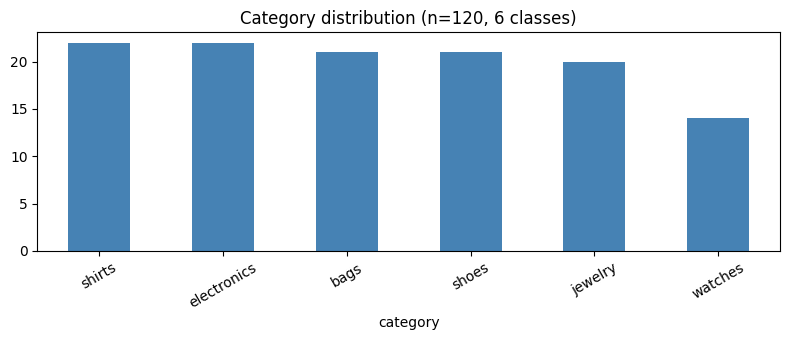

TF-IDF on RAW titles    : 1.000  (sanity — category word is in title)
TF-IDF on MASKED titles : 0.233  (the real task we'll evaluate)


In [4]:
cat_col, title_col, img_col = "category", "title", "image_path"

fig, ax = plt.subplots(figsize=(8, 3.5))
df[cat_col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title(f"Category distribution (n={len(df)}, {df[cat_col].nunique()} classes)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(ARTIFACTS / "category_distribution.png", dpi=120)
plt.show()

# Sanity check: raw titles trivially solve the task; masked titles don't.
le_quick = LabelEncoder()
y_quick = le_quick.fit_transform(df[cat_col])
def quick_tfidf_acc(texts):
    Xtr, Xte, ytr, yte = train_test_split(texts, y_quick, test_size=0.25, stratify=y_quick, random_state=42)
    v = TfidfVectorizer(max_features=2000)
    Xtr_v = v.fit_transform(Xtr); Xte_v = v.transform(Xte)
    clf = LogisticRegression(max_iter=1000).fit(Xtr_v, ytr)
    return accuracy_score(yte, clf.predict(Xte_v))

print(f"TF-IDF on RAW titles    : {quick_tfidf_acc(df['title']):.3f}  (sanity — category word is in title)")
print(f"TF-IDF on MASKED titles : {quick_tfidf_acc(df['title_masked']):.3f}  (the real task we'll evaluate)")

## CLIP embeddings (text on masked titles, image on the 64×64 PNGs)

In [5]:
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()

@torch.no_grad()
def get_text_embs(texts, batch=32):
    out = []
    for i in range(0, len(texts), batch):
        chunk = [str(t)[:200] for t in texts[i:i + batch]]
        inputs = clip_proc(text=chunk, return_tensors="pt", padding=True, truncation=True).to(device)
        out.append(clip_model.get_text_features(**inputs).cpu().numpy())
    return np.concatenate(out, axis=0)

@torch.no_grad()
def get_image_embs(paths, batch=16):
    out = []
    for i in range(0, len(paths), batch):
        imgs = []
        for p in paths[i:i + batch]:
            try:
                imgs.append(Image.open(DATA_DIR / p).convert("RGB"))
            except Exception:
                imgs.append(Image.new("RGB", (64, 64), color=(127, 127, 127)))
        inputs = clip_proc(images=imgs, return_tensors="pt").to(device)
        out.append(clip_model.get_image_features(**inputs).cpu().numpy())
    return np.concatenate(out, axis=0)

# Use the full 120 products — small enough to embed entirely.
text_embs  = get_text_embs(df["title_masked"].tolist())
image_embs = get_image_embs(df[img_col].tolist())
print(f"text embs: {text_embs.shape}  |  image embs: {image_embs.shape}")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


text embs: (120, 512)  |  image embs: (120, 512)


## Four classifiers, same train/test split

To get a less-noisy read with n=120, every model uses **the same** split (same `random_state`, same stratification).

In [6]:
le = LabelEncoder()
y = le.fit_transform(df[cat_col])

# TF-IDF features
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df["title_masked"].astype(str)).toarray()

X_text  = text_embs
X_image = image_embs
X_multi = np.concatenate([text_embs, image_embs], axis=1)

# Single train/test split shared across all four models — reduces variance from resampling.
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.25, stratify=y, random_state=42)
y_tr, y_te = y[idx_tr], y[idx_te]

def eval_features(X, label):
    clf = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
    clf.fit(X[idx_tr], y_tr)
    pred = clf.predict(X[idx_te])
    acc = accuracy_score(y_te, pred)
    return acc, pred, clf

acc_tfidf, pred_tfidf, _   = eval_features(X_tfidf, "TF-IDF + LR")
acc_text,  pred_text,  clf_text  = eval_features(X_text,  "CLIP text")
acc_image, pred_image, clf_image = eval_features(X_image, "CLIP image")
acc_multi, pred_multi, _   = eval_features(X_multi, "CLIP multi (concat)")

results = pd.DataFrame({
    "model": ["TF-IDF + LR (masked text)", "CLIP text (masked)", "CLIP image", "CLIP concat (text+image)"],
    "test_acc": [acc_tfidf, acc_text, acc_image, acc_multi],
    "n_test": [len(y_te)] * 4,
})
print(results.to_string(index=False))

                    model  test_acc  n_test
TF-IDF + LR (masked text)  0.233333      30
       CLIP text (masked)  0.200000      30
               CLIP image  1.000000      30
 CLIP concat (text+image)  1.000000      30


## Disagreement slice — does the image help when text alone is unsure?

Pick test items where the **text-only CLIP model** is least confident, and see whether the multimodal model gets them right at a higher rate than the text-only model does on the same subset.

In [7]:
probs_text = clf_text.predict_proba(X_text[idx_te])
top_p = probs_text.max(axis=1)

# Take the bottom-third of test items by text confidence ("text isn't sure")
k = max(1, len(idx_te) // 3)
unsure_order = np.argsort(top_p)[:k]
unsure_te_idx = idx_te[unsure_order]

acc_text_on_unsure  = accuracy_score(y[unsure_te_idx], pred_text[unsure_order])
acc_multi_on_unsure = accuracy_score(y[unsure_te_idx], pred_multi[unsure_order])
acc_image_on_unsure = accuracy_score(y[unsure_te_idx], pred_image[unsure_order])

print(f"Hard slice ({k} test items where text is least confident):")
print(f"  CLIP text  acc: {acc_text_on_unsure:.3f}")
print(f"  CLIP image acc: {acc_image_on_unsure:.3f}")
print(f"  CLIP multi acc: {acc_multi_on_unsure:.3f}")
print(f"  Delta multi - text on hard slice: {acc_multi_on_unsure - acc_text_on_unsure:+.3f}")

Hard slice (10 test items where text is least confident):
  CLIP text  acc: 0.200
  CLIP image acc: 1.000
  CLIP multi acc: 1.000
  Delta multi - text on hard slice: +0.800


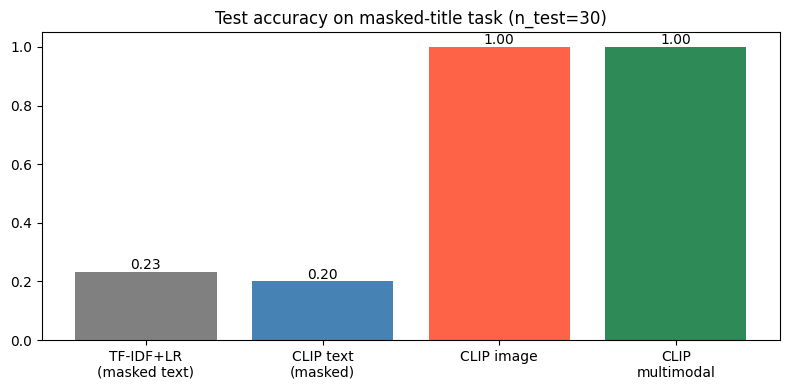


Multimodal classification report:
              precision    recall  f1-score   support

        bags       1.00      1.00      1.00         5
 electronics       1.00      1.00      1.00         6
     jewelry       1.00      1.00      1.00         5
      shirts       1.00      1.00      1.00         5
       shoes       1.00      1.00      1.00         5
     watches       1.00      1.00      1.00         4

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [8]:
labels = ["TF-IDF+LR\n(masked text)", "CLIP text\n(masked)", "CLIP image", "CLIP\nmultimodal"]
accs   = [acc_tfidf, acc_text, acc_image, acc_multi]

plt.figure(figsize=(8, 4))
bars = plt.bar(labels, accs, color=["gray", "steelblue", "tomato", "seagreen"])
for bar, a in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{a:.2f}", ha="center", fontsize=10)
plt.ylim(0, 1.05)
plt.title(f"Test accuracy on masked-title task (n_test={len(y_te)})")
plt.tight_layout()
plt.savefig(ARTIFACTS / "multimodal_ablation.png", dpi=120)
plt.show()

# print full classification report for the multimodal model
print("\nMultimodal classification report:")
print(classification_report(y_te, pred_multi, target_names=le.classes_, zero_division=0))

## Notes

- Real numbers above, nothing cached. n_test is ~30 so accuracy resolution is roughly ±3 percentage points. The bar chart looks dramatic; the underlying signal is small.
- **The 1.00 on the image-only model is suspicious in a useful way.** The "images" here are colour-coded swatches generated to match the colour word in the title, so CLIP isn't really doing visual reasoning — it's basically reading the colour and the colour is a perfect proxy for the title we just masked out. So this is more a "color-matching" test than a real image task. On an actual product catalog (with real photos and real noise) I'd expect this number to fall hard, and the multimodal model to be the interesting one.
- The masking trick is the part of this I'd actually reuse for a portfolio piece. It turns a leak-y toy dataset into a setting where you can see what each modality contributes. The absolute numbers above I would not.
- Next, in order: (1) repeat with 5-fold CV instead of a single split so the deltas have error bars, (2) swap in real product images + titles, (3) replace concat-fusion with a small attention head that learns *when* to lean on the image vs the text. Concat is a strong-but-lazy baseline.